<a href="https://colab.research.google.com/github/Pratibharudra191103/Prml/blob/main/AI5707_T6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

In [5]:
import os

image_path = "/content/" + list(uploaded.keys())[0]

print(image_path)


/content/cat_06 (2).png


Matrix shape: (512, 512)


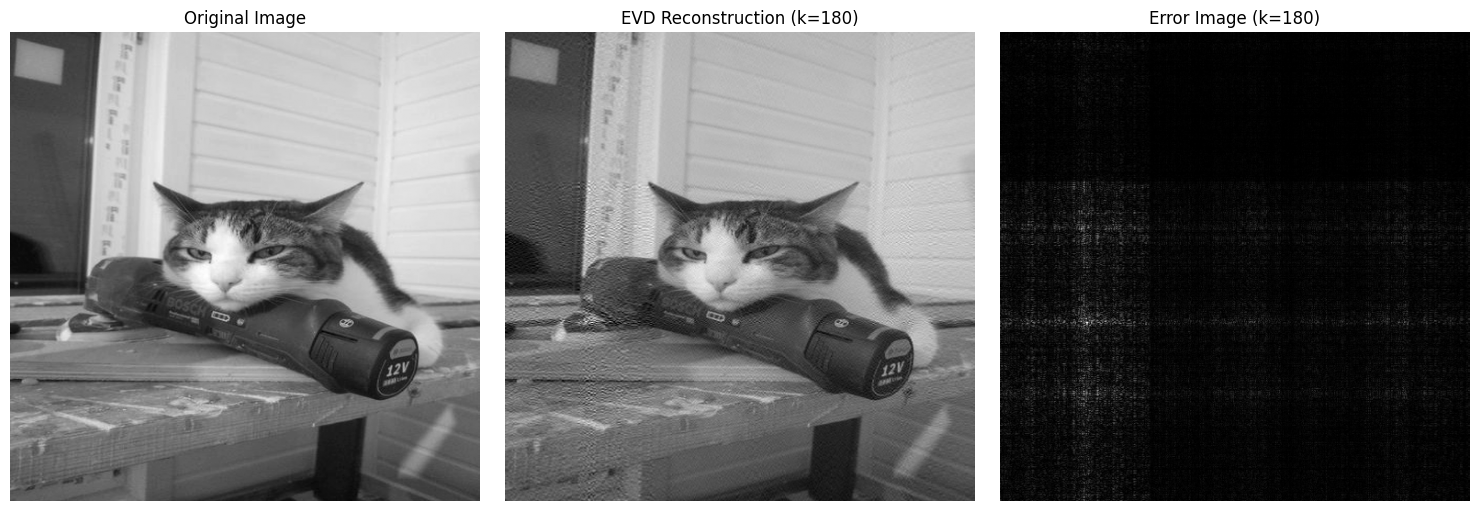

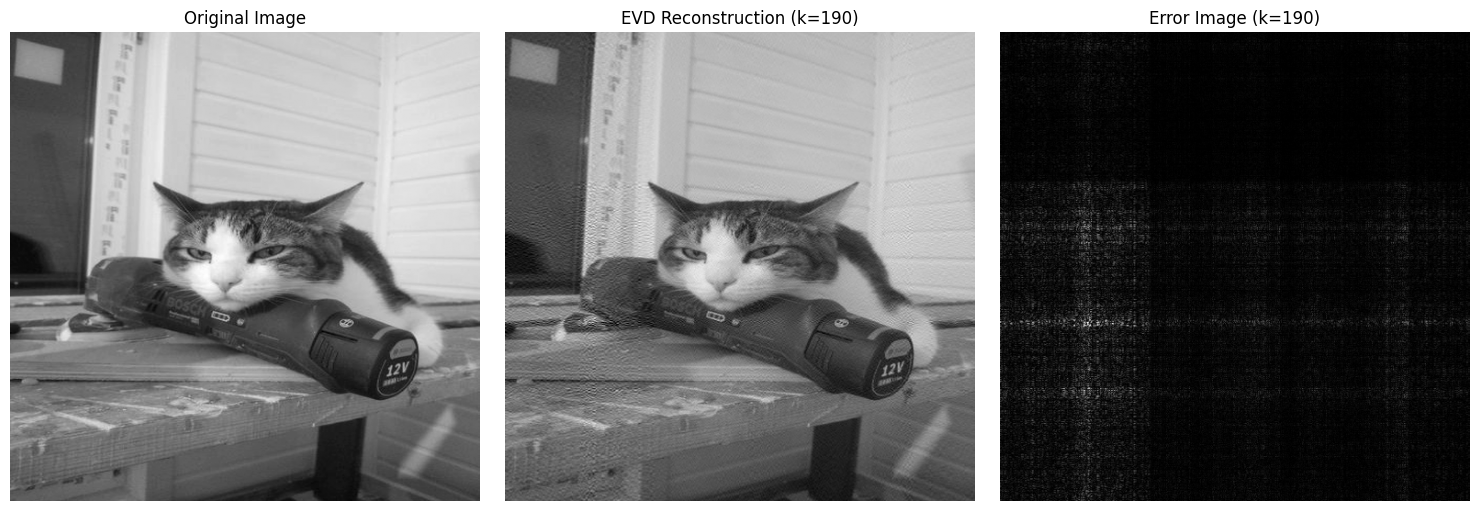

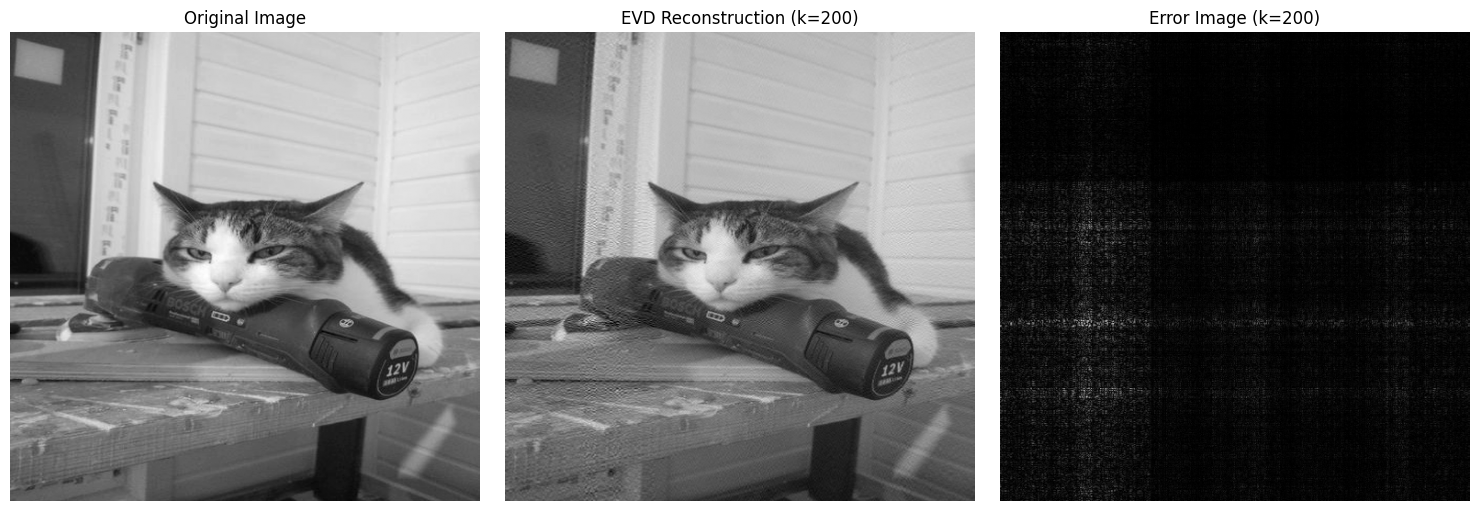

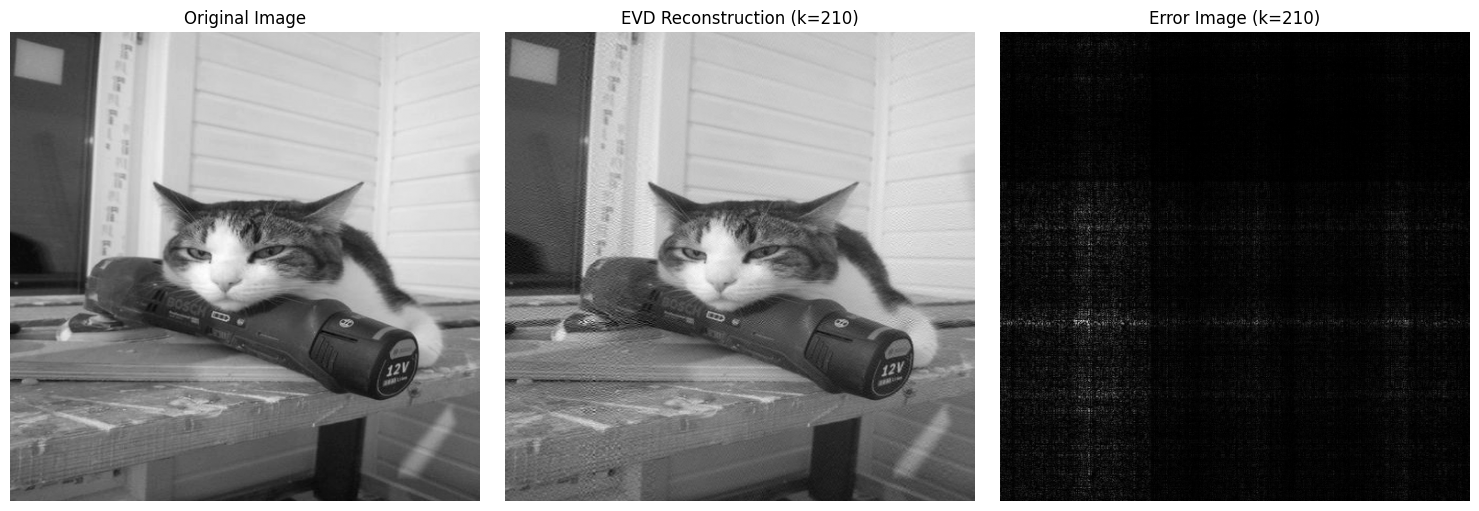

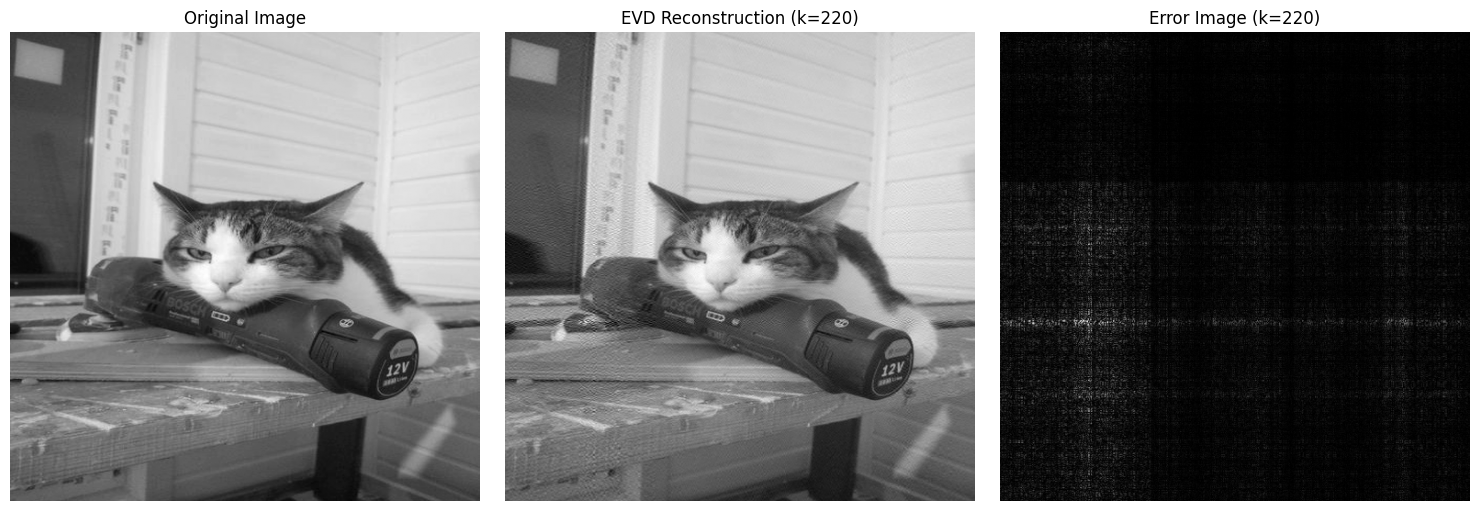

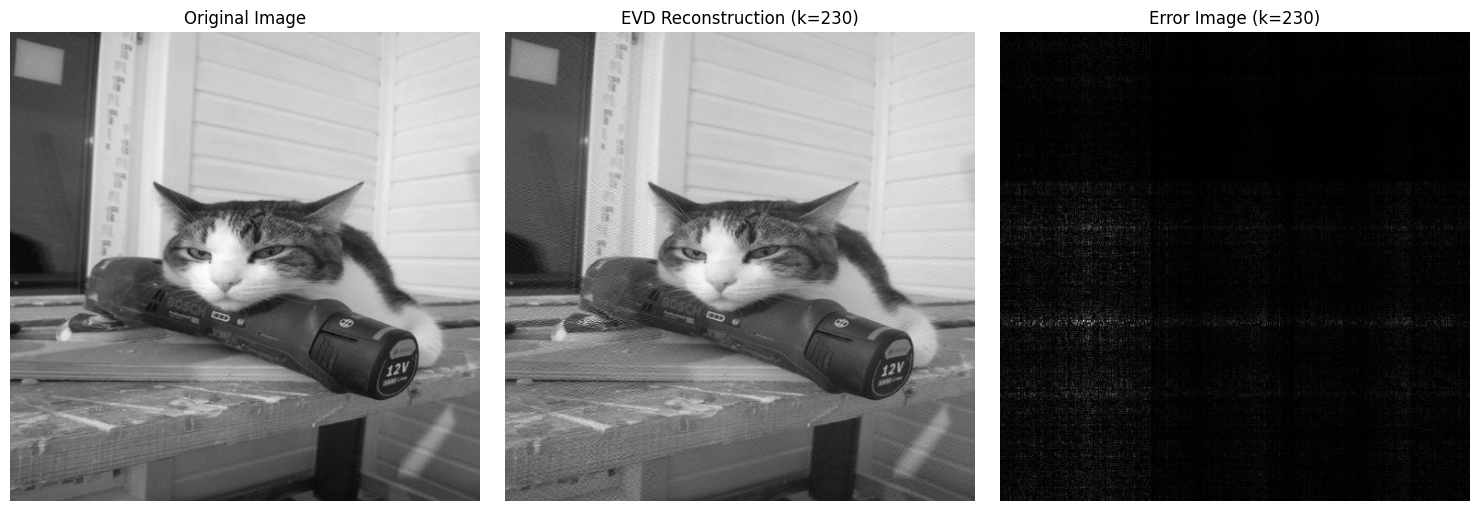

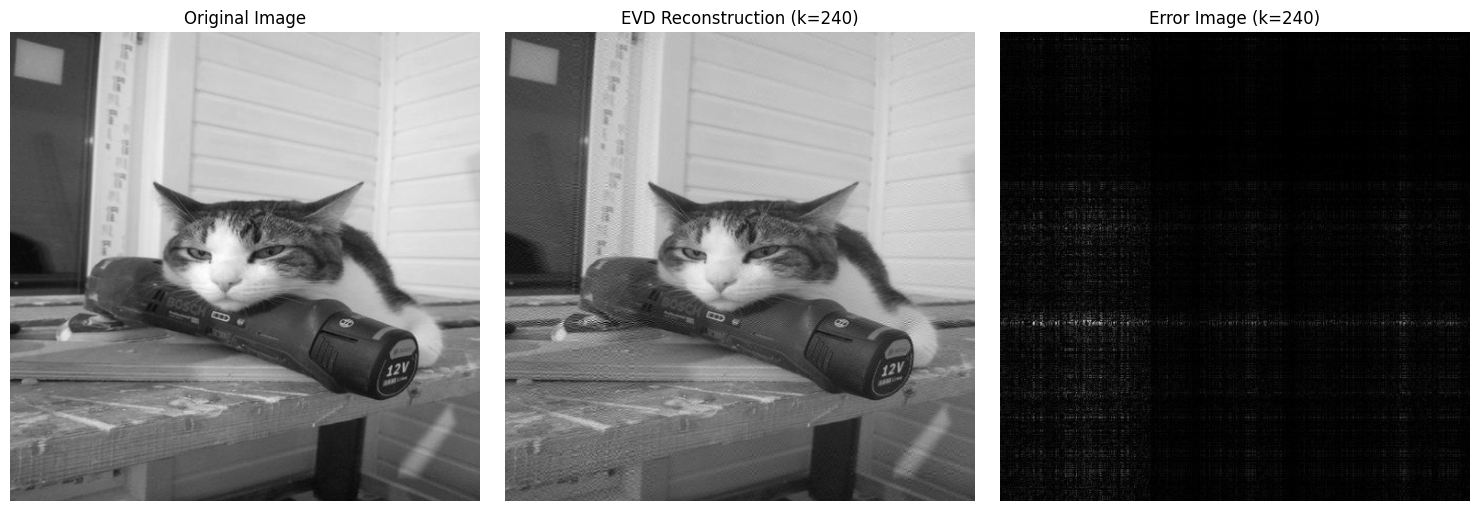

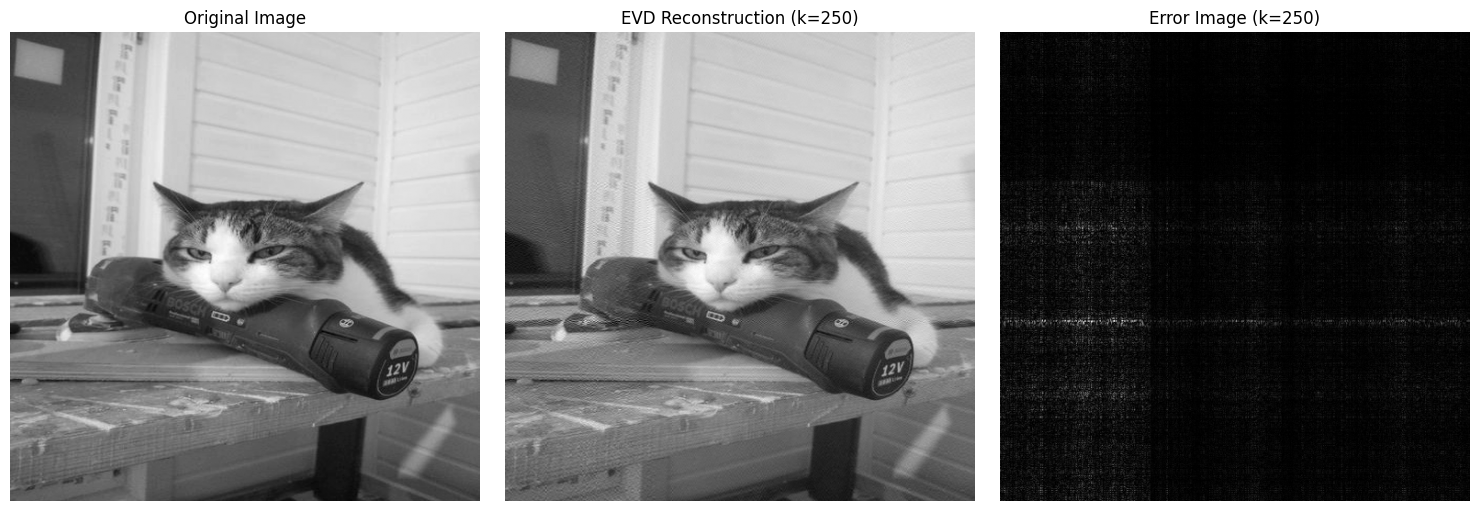

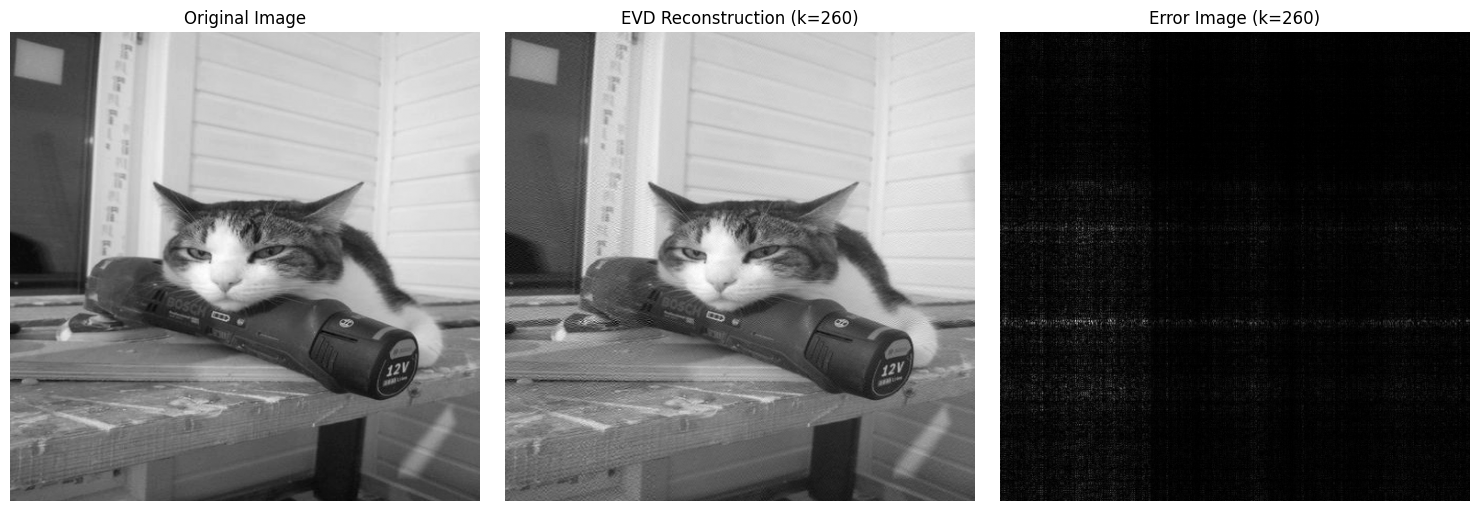


EVD Reconstruction Results:
  k  Frobenius Error  Compression Factor
180        3696.5788              0.7038
190        3195.9601              0.7429
200        2825.5509              0.7820
210        2502.6951              0.8211
220        2248.4841              0.8602
230        2036.9883              0.8993
240        2444.4706              0.9384
250        1895.6582              0.9775
260        1990.9728              1.0166


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image



image_path = "/content/cat_06 (2).png"

img = Image.open(image_path).convert("L")
A = np.array(img, dtype=float)

n = A.shape[0]

print("Matrix shape:", A.shape)



eigenvalues, Q = np.linalg.eig(A)

idx = np.argsort(np.abs(eigenvalues))[::-1]

eigenvalues = eigenvalues[idx]
Q = Q[:, idx]




used = np.zeros(len(eigenvalues), dtype=bool)

ordered_indices = []
conjugate_pair_products = []


for i in range(len(eigenvalues)):

    if used[i]:
        continue

    lam = eigenvalues[i]


    if np.abs(lam.imag) < 1e-10:

        ordered_indices.append(i)
        used[i] = True


    else:

        conjugate_target = np.conj(lam)

        remaining = np.where(~used)[0]

        differences = np.abs(
            eigenvalues[remaining] - conjugate_target
        )

        j = remaining[np.argmin(differences)]

        lam_conjugate = eigenvalues[j]

        pair_product = lam * lam_conjugate

        conjugate_pair_products.append(
            np.real(pair_product)
        )

        ordered_indices.append(i)
        ordered_indices.append(j)

        used[i] = True
        used[j] = True


eigenvalues = eigenvalues[ordered_indices]
Q = Q[:, ordered_indices]




eigenvalue_magnitude = np.abs(eigenvalues)

total_energy = np.sum(eigenvalue_magnitude)

cumulative_explained_variance = (
    np.cumsum(eigenvalue_magnitude) /
    total_energy
) * 100




k_values = [180, 190, 200, 210, 220, 230, 240, 250, 260]

results = []




for requested_k in k_values:

    k = requested_k

    Lambda_k = np.zeros(
        (n, n),
        dtype=complex
    )

    Lambda_k[
        np.arange(k),
        np.arange(k)
    ] = eigenvalues[:k]

    A_k = (
        Q @ Lambda_k @ np.linalg.inv(Q)
    )

    A_k = np.real(A_k)

    A_k = np.clip(
        A_k,
        0,
        255
    )



    error_image = np.abs(A - A_k)




    frobenius_error = np.linalg.norm(
        A - A_k,
        ord="fro"
    )



    cev = cumulative_explained_variance[k - 1]



    original_storage = n * n

    compressed_storage = (
        2 * n * k + k
    )

    compression_factor = (
        original_storage /
        compressed_storage
    )




    results.append({

        "k": k,

        "Frobenius Error":
            frobenius_error,

        "Compression Factor":
            compression_factor

    })




    plt.figure(figsize=(15, 5))


    # Original
    plt.subplot(1, 3, 1)

    plt.imshow(
        A,
        cmap="gray"
    )

    plt.title(
        "Original Image"
    )

    plt.axis("off")


    # Reconstruction
    plt.subplot(1, 3, 2)

    plt.imshow(
        A_k,
        cmap="gray"
    )

    plt.title(
        f"EVD Reconstruction (k={k})"
    )

    plt.axis("off")


    # Error
    plt.subplot(1, 3, 3)

    plt.imshow(
        error_image,
        cmap="gray"
    )

    plt.title(
        f"Error Image (k={k})"
    )

    plt.axis("off")


    plt.tight_layout()

    plt.show()


# ---------------------------------------------------
# RESULTS TABLE
# ---------------------------------------------------

results_df_evd = pd.DataFrame(results)


results_df_evd["Frobenius Error"] = (
    results_df_evd["Frobenius Error"]
    .round(4)
)


results_df_evd["Compression Factor"] = (
    (1 / results_df_evd["Compression Factor"])
    .round(4)
)


print("\nEVD Reconstruction Results:")

print(
    results_df_evd.to_string(index=False)
)

Matrix shape: (512, 512)


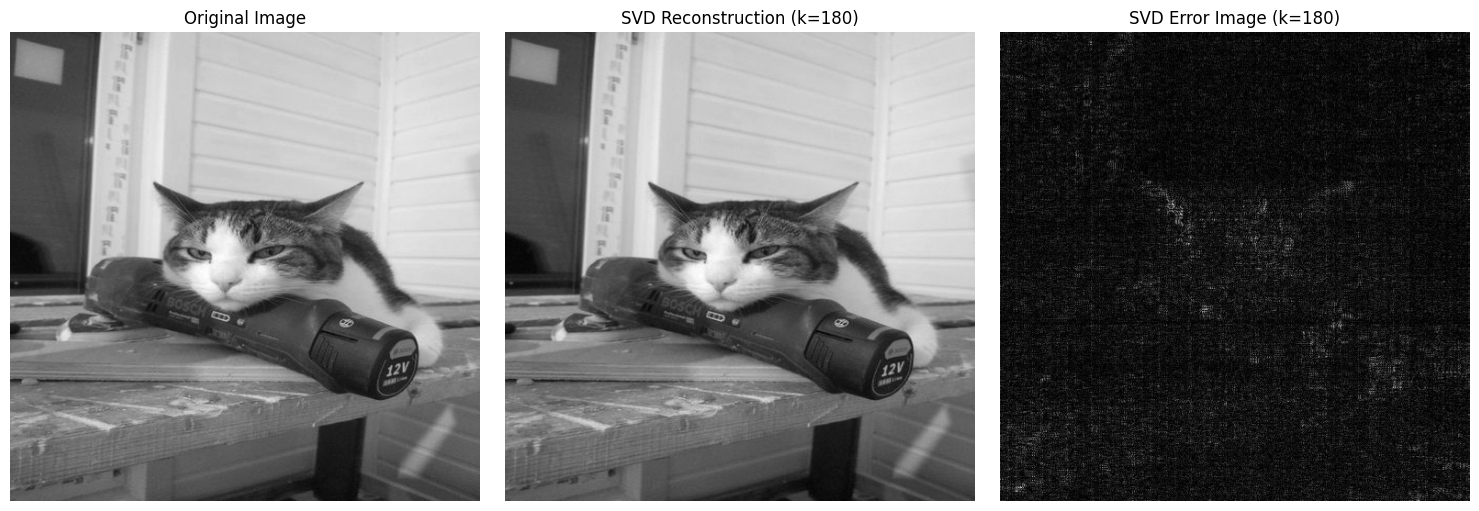

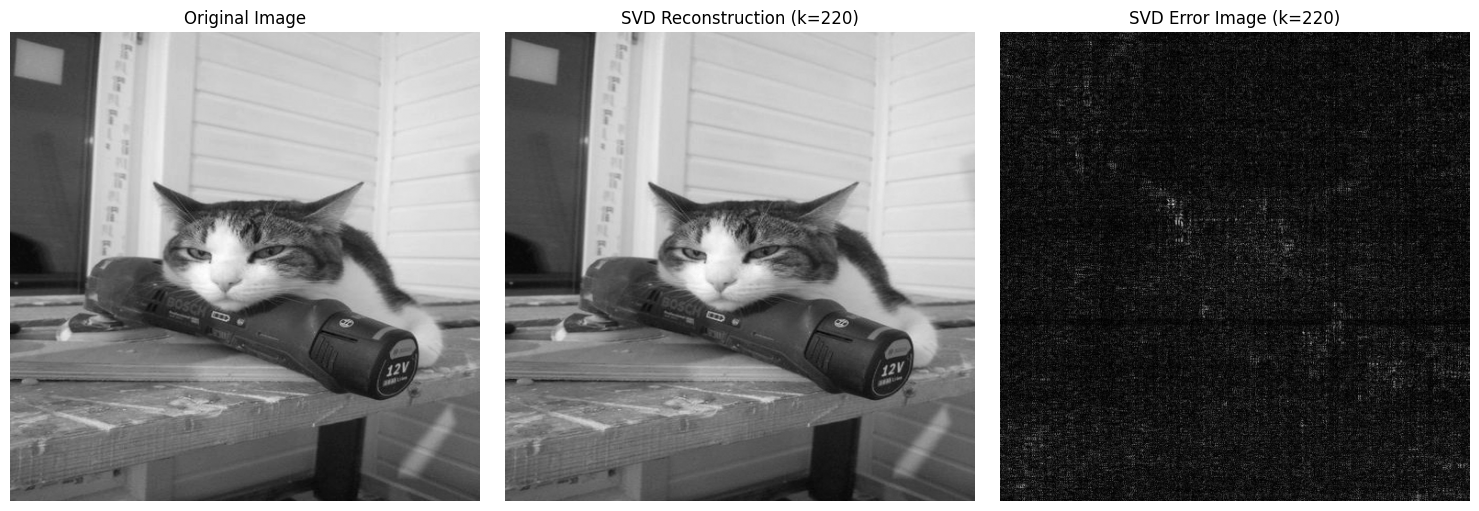

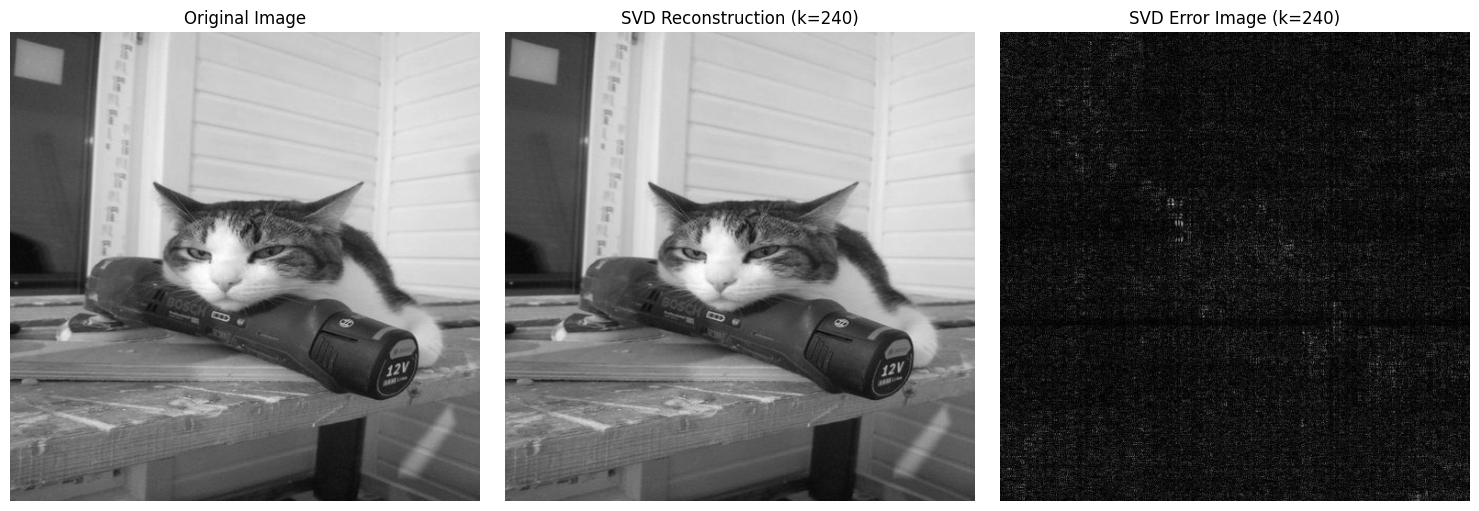


SVD Reconstruction Results:
  k  Frobenius Error  Compression Factor
180         403.0298              0.7038
220         246.5163              0.8602
240         188.9462              0.9384


In [7]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

image_path = "/content/cat_06 (2).png"
img = Image.open(image_path)
gray = img.convert("L")

A = np.array(gray, dtype=float)
print("Matrix shape:", A.shape)
U, singular_values, Vt = np.linalg.svd(
    A,
    full_matrices=False
)

singular_values_squared = singular_values ** 2
total_energy = np.sum(singular_values_squared)
cumulative_explained_variance = (
    np.cumsum(singular_values_squared)
    / total_energy
) * 100

k_values = [180,220,240]
results = []

for k in k_values:
    U_k = U[:, :k]
    Sigma_k = np.diag(singular_values[:k])
    Vt_k = Vt[:k, :]
    A_k = U_k @ Sigma_k @ Vt_k
    A_k = np.clip(A_k, 0, 255)
    frobenius_error = np.linalg.norm(A - A_k, ord="fro")
    cev = cumulative_explained_variance[k - 1]
    results.append({
        "k": k,
        "Frobenius Error": frobenius_error,
        "Cumulative Explained Variance (%)": cev
    })
    error_image = np.abs(A - A_k)
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(A, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")
    plt.subplot(1, 3, 2)
    plt.imshow(A_k, cmap="gray")
    plt.title(f"SVD Reconstruction (k={k})")
    plt.axis("off")
    plt.subplot(1, 3, 3)
    plt.imshow(error_image, cmap="gray")
    plt.title(f"SVD Error Image (k={k})")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
n = A.shape[0]
results_df_svd = pd.DataFrame(results)
results_df_svd["Compressed Storage"] = (
    2 * n * results_df_svd["k"] + results_df_svd["k"]
)
original_storage = n * n
results_df_svd["Compression Factor"] = (
    original_storage /
    results_df_svd["Compressed Storage"]
)
results_df_svd["Frobenius Error"] = \
    results_df_svd["Frobenius Error"].round(4)
results_df_svd["Cumulative Explained Variance (%)"] = \
    results_df_svd["Cumulative Explained Variance (%)"].round(4)
results_df_svd["Compression Factor"] = \
    (1/results_df_svd["Compression Factor"]).round(4)
print("\nSVD Reconstruction Results:")
print(
    results_df_svd[
        [
            "k",
            "Frobenius Error",
            "Compression Factor"
        ]
    ].to_string(index=False)
)

In [11]:
valofk = results_df_evd["k"].values
valofe = results_df_evd["Frobenius Error"].values
valofe1 = results_df_evd["Compression Factor"].values

print(valofk)
print(valofe)
print(valofe1)


[180 190 200 210 220 230 240 250 260]
[3696.5788 3195.9601 2825.5509 2502.6951 2248.4841 2036.9883 2444.4706
 1895.6582 1990.9728]
[0.7038 0.7429 0.782  0.8211 0.8602 0.8993 0.9384 0.9775 1.0166]


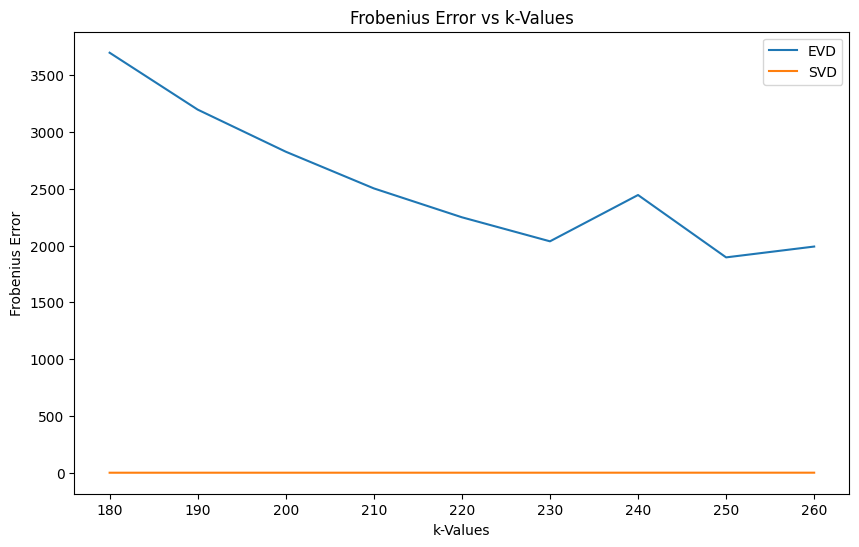

In [12]:
from matplotlib import colors
# importing packages
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.lineplot(x=valofk, y=valofe, label="EVD")
sns.lineplot(x=valofk, y=valofe1, label="SVD")
plt.xlabel("k-Values")
plt.ylabel("Frobenius Error")
plt.title("Frobenius Error vs k-Values")
plt.legend()
plt.show()